# ЛР4. Бинарная классификация
**Данные:** Healthy Meal Plan (500 блюд). **Цель:** по параметрам блюда предсказать `is_healthy` (1 — здоровое, 0 — нет).

**План (по пунктам задания):**
1. Импорт датасета.
2. Очистка (пропуски, дубликаты, выбросы) и масштабирование.
3. Целевая переменная и признаки.
4. Три модели: логистическая регрессия, SVM, CART.
5. Оценка качества: accuracy, precision, recall, F1, ROC-AUC, матрицы ошибок.

*Запуск: Run All (ячейки сверху вниз). Файл `healthy_meal_plans.csv` лежит рядом с ноутбуком.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

%matplotlib inline
SEED = 15
FIG = os.path.join(os.getcwd(), "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})


def metrics(y_true, y_pred, y_score):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred), f1=f1_score(y_true, y_pred), roc_auc=roc_auc_score(y_true, y_score))

## Шаг 1. Импорт датасета
Читаем CSV и смотрим, что в нём лежит и как распределена цель. Цель бинарная (0/1), поэтому датасет подходит.

In [2]:
df = pd.read_csv("healthy_meal_plans.csv")
print("Размер:", df.shape, "(строк, столбцов)")
print("Столбцы:", list(df.columns), "\n")
print("Первые 3 блюда:")
for _, r in df.head(3).iterrows():
    print(f"  {r['meal_name']:20s} калории={r['calories']:.2f}  белок={r['protein']:.2f}  жир={r['fat']:.2f}  углеводы={r['carbs']:.2f}  -> is_healthy = {r['is_healthy']}")
vc = df["is_healthy"].value_counts().sort_index()
print(f"\nis_healthy = 0: {vc[0]} блюд ({vc[0]/len(df):.1%}),  is_healthy = 1: {vc[1]} блюд ({vc[1]/len(df):.1%})")

Размер: (500, 14) (строк, столбцов)
Столбцы: ['meal_name', 'num_ingredients', 'calories', 'prep_time', 'protein', 'fat', 'carbs', 'vegan', 'vegetarian', 'keto', 'paleo', 'gluten_free', 'mediterranean', 'is_healthy'] 

Первые 3 блюда:
  Gluten-Free Pasta    калории=0.49  белок=0.78  жир=0.60  углеводы=0.44  -> is_healthy = 1
  Grilled Salmon       калории=0.16  белок=0.14  жир=0.65  углеводы=0.05  -> is_healthy = 0
  Lentil Soup          калории=0.70  белок=0.62  жир=0.61  углеводы=0.00  -> is_healthy = 0

is_healthy = 0: 453 блюд (90.6%),  is_healthy = 1: 47 блюд (9.4%)


**Что видно.** Здоровых блюд всего ~9%: классы **несбалансированы**. Из-за этого обычная accuracy обманчива: модель «всегда отвечай 0» уже даёт 91%, но ничего не находит. Поэтому дальше смотрим precision, recall и F1 именно по классу «здоровое».

## Шаг 2. Очистка: пропуски, дубликаты, выбросы, масштаб
Проверяем три вещи: пустые значения, повторяющиеся строки и выбросы по правилу IQR (значение вне `[Q1 − 1.5·IQR; Q3 + 1.5·IQR]`).

In [3]:
print("Пропусков всего:", int(df.isna().sum().sum()))
print("Полных дубликатов строк:", int(df.duplicated().sum()))
num = ["num_ingredients", "calories", "prep_time", "protein", "fat", "carbs"]
print("\nВыбросы по IQR:")
for col in num:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    k = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
    print(f"  {col:16s} допустимо [{q1 - 1.5*iqr:6.3f}; {q3 + 1.5*iqr:6.3f}]   выбросов: {k}")
print("\nВсе числовые признаки уже в диапазоне [0; 1]:", bool((df[num].min() >= 0).all() and (df[num].max() <= 1).all()))

Пропусков всего: 0
Полных дубликатов строк: 0

Выбросы по IQR:
  num_ingredients  допустимо [-0.409;  1.409]   выбросов: 0
  calories         допустимо [-0.547;  1.531]   выбросов: 0
  prep_time        допустимо [-0.560;  1.520]   выбросов: 0
  protein          допустимо [-0.555;  1.556]   выбросов: 0
  fat              допустимо [-0.482;  1.491]   выбросов: 0
  carbs            допустимо [-0.492;  1.490]   выбросов: 0

Все числовые признаки уже в диапазоне [0; 1]: True


**Что видно.** Пропусков, дубликатов и выбросов нет, чистить нечего. Признаки уже нормализованы в [0; 1] автором датасета. Для логистической регрессии и SVM всё равно добавим `StandardScaler` внутрь pipeline: он обучается только на обучающей части, поэтому данные теста не «подсматриваются» (нет утечки).

## Шаг 3. Целевая переменная и признаки
Цель — `is_healthy`. Признаки — остальные 12 столбцов; `meal_name` — просто название блюда (текст), в признаки не берём. Разбиваем на обучение (80%) и тест (20%) **стратифицированно**, чтобы доля здоровых блюд в обеих частях была одинаковой.

Признаки (12): ['num_ingredients', 'calories', 'prep_time', 'protein', 'fat', 'carbs', 'vegan', 'vegetarian', 'keto', 'paleo', 'gluten_free', 'mediterranean']

Корреляция признака с целью (Пирсон), от отрицательной к положительной:
  fat              -0.191
  carbs            -0.103
  mediterranean    -0.078
  num_ingredients  -0.027
  calories         -0.021
  keto             -0.017
  paleo            -0.003
  vegetarian       +0.014
  gluten_free      +0.016
  vegan            +0.019
  prep_time        +0.048
  protein          +0.061

Обучение: 400 блюд (здоровых 38),  тест: 100 блюд (здоровых 9)


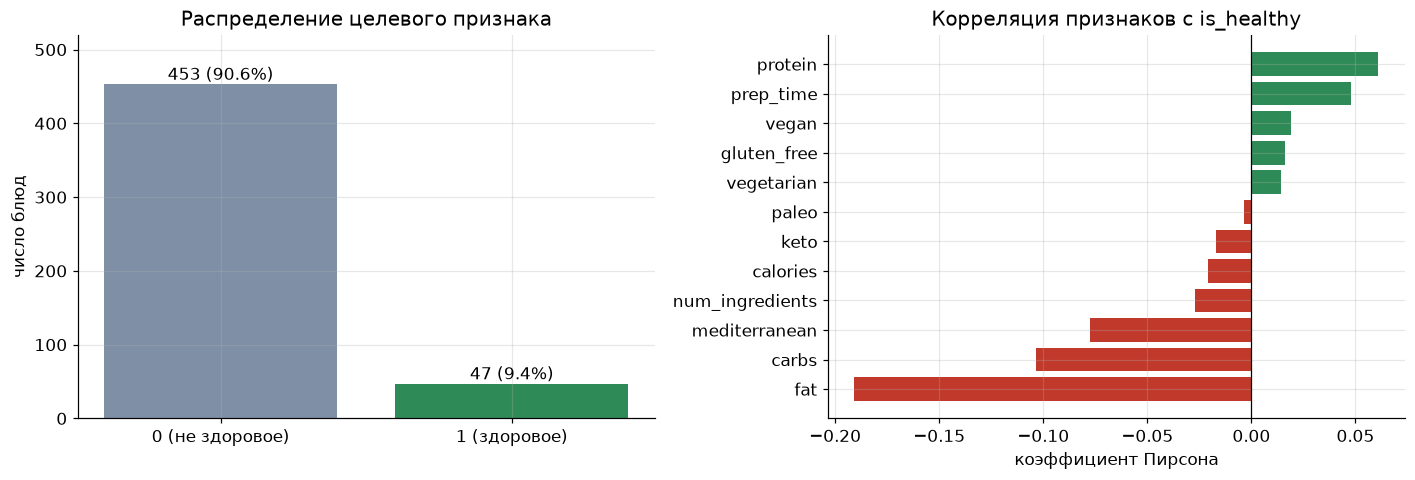

In [4]:
X = df.drop(columns=["is_healthy", "meal_name"])
y = df["is_healthy"]
print("Признаки (12):", list(X.columns))
print("\nКорреляция признака с целью (Пирсон), от отрицательной к положительной:")
for k, v in X.corrwith(y).sort_values().items():
    print(f"  {k:16s} {v:+.3f}")

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"\nОбучение: {len(Xtr)} блюд (здоровых {ytr.sum()}),  тест: {len(Xte)} блюд (здоровых {yte.sum()})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(["0 (не здоровое)", "1 (здоровое)"], vc.values, color=["#7f8fa6", "#2e8b57"])
for i, v in enumerate(vc.values):
    ax[0].text(i, v + 6, f"{v} ({v/len(df):.1%})", ha="center")
ax[0].set_title("Распределение целевого признака"); ax[0].set_ylabel("число блюд"); ax[0].set_ylim(0, 520)
cr = X.corrwith(y).sort_values()
ax[1].barh(cr.index, cr.values, color=np.where(cr.values < 0, "#c0392b", "#2e8b57"))
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_title("Корреляция признаков с is_healthy"); ax[1].set_xlabel("коэффициент Пирсона")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "01_target_and_corr.png")); plt.show()

**Что видно на графиках.**
- **Слева:** огромный перекос: столбец «не здоровое» (453) почти в десять раз выше «здорового» (47).
- **Справа:** у каждого признака корреляция с целью слабая (самая заметная — у `fat`: −0.19; у большинства признаков почти 0). Нет одного признака, который бы всё объяснял: «здоровье» зависит от **сочетания** калорий, жиров, белков и углеводов, то есть связь нелинейная. Это важно для выбора модели: линейная регрессия будет слабой, а дерево должно справиться лучше.

## Шаг 4. Модели
Обучаем три семейства моделей:
- **Логистическая регрессия** — линейная: вес на каждый признак, граница между классами — прямая (плоскость).
- **SVM (ядро RBF)** — ищет границу максимального зазора, с ядром RBF граница может быть кривой.
- **CART (дерево решений)** — серия вопросов «признак > порога?», разбивает пространство на прямоугольники.

Для каждой — вариант с `class_weight='balanced'` (редкому классу даётся больший вес, чтобы модель не игнорировала его). Для SVM и CART параметры подбираем через `GridSearchCV` по F1 на 5-кратной кросс-валидации (только на обучающей части). Для сравнения добавлен **baseline** «всегда 0».

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
models = {
    "Baseline (всегда 0)": DummyClassifier(strategy="most_frequent"),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "LogReg balanced": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=SEED)),
    "SVM (RBF) balanced": make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
    "CART (default)": DecisionTreeClassifier(random_state=SEED),
}
grid = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                    {"max_depth": [3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 3, 5, 10]}, scoring="f1", cv=cv).fit(Xtr, ytr)
print("CART: лучшие параметры", grid.best_params_, f"(F1 на кросс-валидации = {grid.best_score_:.3f})")
models["CART (tuned, balanced)"] = grid.best_estimator_

gsvm = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")),
                    {"svc__C": [0.1, 1, 10, 100, 1000], "svc__gamma": [0.01, 0.03, 0.1, 0.3, 1]}, scoring="f1", cv=cv).fit(Xtr, ytr)
print("SVM : лучшие параметры", gsvm.best_params_, f"(F1 на кросс-валидации = {gsvm.best_score_:.3f})")
models["SVM (tuned, balanced)"] = gsvm.best_estimator_

res, scores = {}, {}
for name, m in models.items():
    m.fit(Xtr, ytr)
    pred = m.predict(Xte)
    s = m.predict_proba(Xte)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xte)
    mt = metrics(yte, pred, s)
    cvs = cross_validate(m, Xtr, ytr, cv=cv, scoring=["f1"])
    mt["cv_f1"] = cvs["test_f1"].mean()
    mt["train_acc"] = accuracy_score(ytr, m.predict(Xtr))
    res[name] = mt; scores[name] = (pred, s)
print("\nВсе модели обучены:", ", ".join(models))

CART: лучшие параметры {'max_depth': 8, 'min_samples_leaf': 1} (F1 на кросс-валидации = 0.898)
SVM : лучшие параметры {'svc__C': 10, 'svc__gamma': 0.03} (F1 на кросс-валидации = 0.525)

Все модели обучены: Baseline (всегда 0), LogReg, LogReg balanced, SVM (RBF), SVM (RBF) balanced, CART (default), CART (tuned, balanced), SVM (tuned, balanced)


## Шаг 5. Оценка качества
Метрики считаем на тесте (100 блюд, которых модель не видела). Как их читать:
- **precision** — из всего, что модель назвала «здоровым», какая доля правда здоровая;
- **recall** — из всех настоящих здоровых блюд, какую долю модель нашла;
- **F1** — среднее между ними (главная метрика при несбалансированных классах);
- **ROC-AUC** — качество ранжирования: 0.5 — случайно, 1.0 — идеально.

Baseline (всегда 0)      accuracy=0.91  precision=0.00  recall=0.00  F1=0.00  ROC-AUC=0.50   | F1 на кросс-вал.=0.00  accuracy на обучении=0.91
LogReg                   accuracy=0.91  precision=0.00  recall=0.00  F1=0.00  ROC-AUC=0.69   | F1 на кросс-вал.=0.00  accuracy на обучении=0.91
LogReg balanced          accuracy=0.65  precision=0.16  recall=0.67  F1=0.26  ROC-AUC=0.69   | F1 на кросс-вал.=0.22  accuracy на обучении=0.67
SVM (RBF)                accuracy=0.91  precision=0.00  recall=0.00  F1=0.00  ROC-AUC=0.81   | F1 на кросс-вал.=0.00  accuracy на обучении=0.91
SVM (RBF) balanced       accuracy=0.84  precision=0.29  recall=0.56  F1=0.38  ROC-AUC=0.81   | F1 на кросс-вал.=0.47  accuracy на обучении=0.91
CART (default)           accuracy=0.92  precision=0.57  recall=0.44  F1=0.50  ROC-AUC=0.71   | F1 на кросс-вал.=0.65  accuracy на обучении=1.00
CART (tuned, balanced)   accuracy=0.96  precision=0.86  recall=0.67  F1=0.75  ROC-AUC=0.83   | F1 на кросс-вал.=0.90  accuracy на обучен

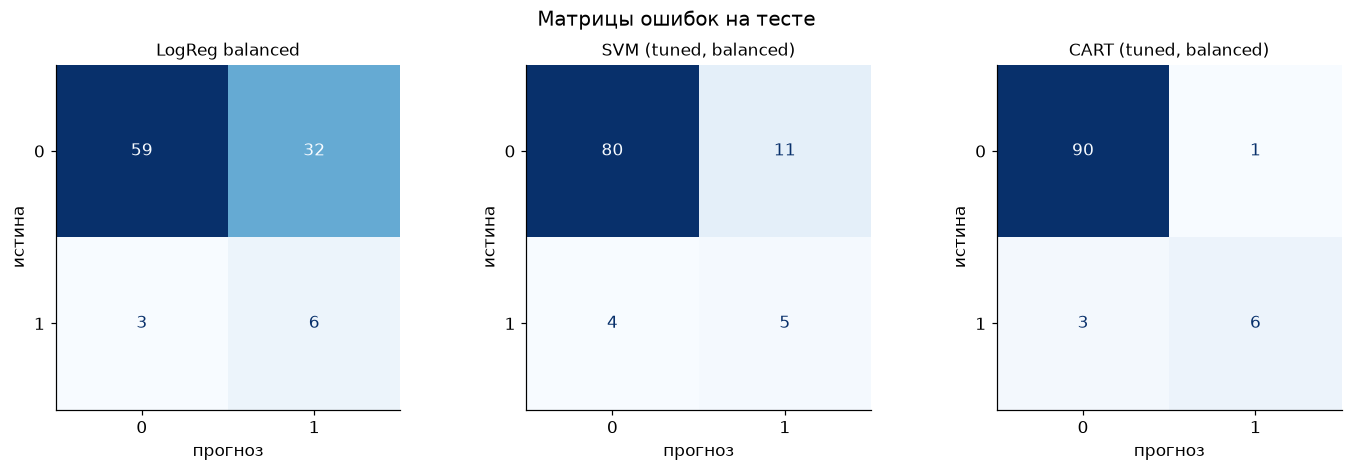

In [6]:
for name, m in res.items():
    print(f"{name:24s} accuracy={m['accuracy']:.2f}  precision={m['precision']:.2f}  recall={m['recall']:.2f}  "
          f"F1={m['f1']:.2f}  ROC-AUC={m['roc_auc']:.2f}   | F1 на кросс-вал.={m['cv_f1']:.2f}  accuracy на обучении={m['train_acc']:.2f}")
pd.DataFrame(res).T.round(4).to_csv("results.csv", encoding="utf-8-sig")

print("\nМатрицы ошибок на тесте (TN — верно «нет», FP — ложная тревога, FN — пропущенное здоровое, TP — верно «да»):")
show = ["LogReg balanced", "SVM (tuned, balanced)", "CART (tuned, balanced)"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, name in zip(axes, show):
    cm = confusion_matrix(yte, scores[name][0])
    ConfusionMatrixDisplay(cm, display_labels=["0", "1"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=11); ax.grid(False); ax.set_xlabel("прогноз"); ax.set_ylabel("истина")
    tn, fp, fn, tp = cm.ravel()
    print(f"  {name:24s} TN={tn}  FP={fp}  FN={fn}  TP={tp}")
fig.suptitle("Матрицы ошибок на тесте", fontsize=13)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "02_confusion.png")); plt.show()

**Что видно на матрицах.** По диагонали (слева сверху и справа снизу) — верные ответы, остальное — ошибки. Здоровых блюд в тесте 9, и логистическая регрессия и CART находят по 6 из них (правый нижний угол). Разница в ложных тревогах (правый верхний угол): у логистической регрессии их **32**, у SVM — 11, а у CART всего **1**. Значит, CART находит столько же здоровых блюд, но почти не называет здоровыми лишние.

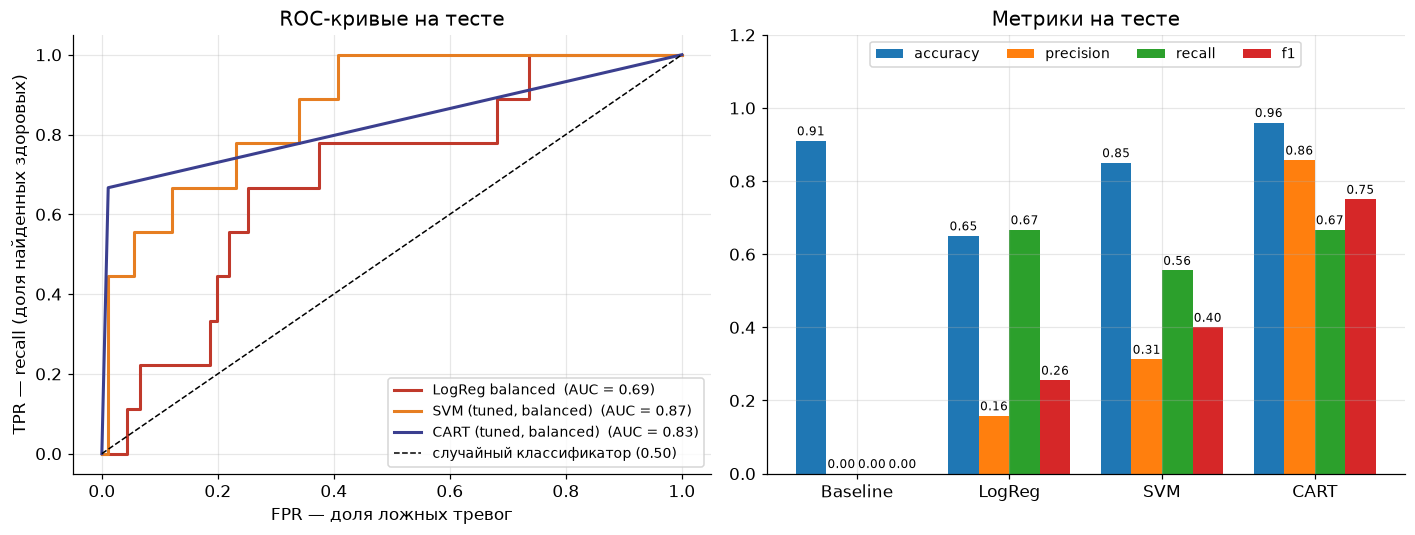

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cols = {"LogReg balanced": "#c0392b", "SVM (tuned, balanced)": "#e67e22", "CART (tuned, balanced)": "#3b3f8f"}
for name, col in cols.items():
    fpr, tpr, _ = roc_curve(yte, scores[name][1])
    axes[0].plot(fpr, tpr, lw=2, color=col, label=f"{name}  (AUC = {res[name]['roc_auc']:.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="случайный классификатор (0.50)")
axes[0].set_xlabel("FPR — доля ложных тревог"); axes[0].set_ylabel("TPR — recall (доля найденных здоровых)")
axes[0].set_title("ROC-кривые на тесте"); axes[0].legend(fontsize=9, loc="lower right")

sel = ["Baseline (всегда 0)", "LogReg balanced", "SVM (tuned, balanced)", "CART (tuned, balanced)"]
w = 0.2
for i, mn in enumerate(["accuracy", "precision", "recall", "f1"]):
    vals = [res[s][mn] for s in sel]
    b = axes[1].bar(np.arange(len(sel)) + i * w, vals, w, label=mn)
    for x, v in zip(np.arange(len(sel)) + i * w, vals):
        axes[1].text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
axes[1].set_xticks(np.arange(len(sel)) + 1.5 * w); axes[1].set_xticklabels(["Baseline", "LogReg", "SVM", "CART"])
axes[1].set_ylim(0, 1.2); axes[1].set_title("Метрики на тесте"); axes[1].legend(ncol=4, loc="upper center", fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "03_04_roc_metrics.png")); plt.show()

**Что видно на графиках.**
- **Слева (ROC):** чем выше и левее кривая, тем лучше; пунктир — случайное угадывание. У SVM кривая выше всех на большей части графика (AUC 0.87). У CART она сразу взлетает до 0.67 при почти нулевых ложных тревогах (AUC 0.83: дальше идёт почти прямая). Кривая логистической регрессии ближе всех к диагонали (AUC 0.69): линейная модель слабо отделяет здоровые блюда.
- **Справа (метрики):** у baseline accuracy высокая (0.91), а precision, recall и F1 равны нулю: он вообще не находит здоровых блюд. Это и есть иллюстрация того, почему одной accuracy мало. У CART все четыре столбца высокие, особенно precision и F1.

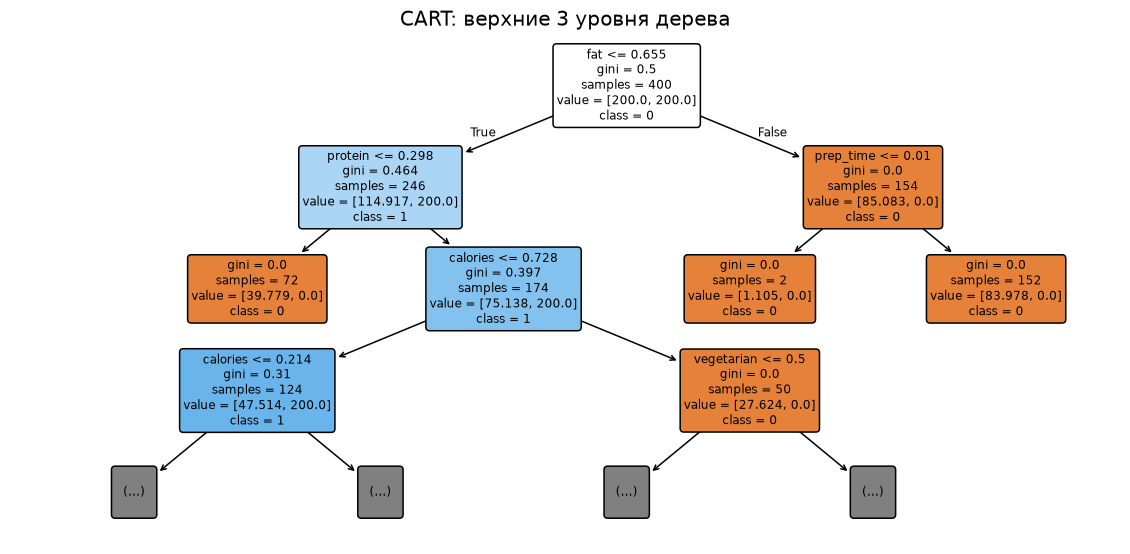

Важность признаков в CART (топ-5):
  calories         0.301
  fat              0.272
  protein          0.254
  carbs            0.099
  num_ingredients  0.074


In [8]:
tree = models["CART (tuned, balanced)"]
fig, ax = plt.subplots(figsize=(13, 6))
plot_tree(tree, feature_names=list(X.columns), class_names=["0", "1"], filled=True, rounded=True, fontsize=8, ax=ax, max_depth=3)
ax.set_title("CART: верхние 3 уровня дерева"); plt.show()
fig.savefig(os.path.join(FIG, "05_tree.png"))

imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Важность признаков в CART (топ-5):")
for k, v in imp.head(5).items():
    print(f"  {k:16s} {v:.3f}")

**Что видно.** Дерево задаёт вопросы про жиры (корень: `fat ≤ 0.655`), белки и калории: цвет узла показывает преобладающий класс (оранжевый — «0», синий — «1», чем темнее, тем увереннее). Главные признаки именно эти четыре, остальные (vegan, keto и т.д.) почти не влияют. Это подтверждает, что «здоровое» блюдо — определённое **сочетание** нутриентов, а не один признак.

## Итог
- Данные чистые: пропусков, дубликатов и выбросов нет; цель несбалансирована (9% здоровых), поэтому смотрим F1, а не accuracy.
- Логистическая регрессия слабая (ROC-AUC ≈ 0.69): граница между классами нелинейная.
- SVM с подобранными параметрами лучше всего ранжирует (ROC-AUC ≈ 0.87), но даёт много ложных тревог.
- **CART — лучшая модель:** accuracy 0.96, precision 0.86, recall 0.67, F1 0.75 (на кросс-валидации F1 ≈ 0.90). Он нашёл большую часть здоровых блюд и почти не ошибался в остальных.
- Дерево на обучении почти идеально (0.998), а на тесте чуть хуже: небольшое переобучение, поэтому глубину и размер листа мы подбирали кросс-валидацией.